# Terra Signal: redundância entre variáveis preditoras (Grupo 1)

Estudo de quais variáveis preditoras carregam a mesma informação. O notebook 04 avaliou cada variável contra `Churn`; aqui comparamos as variáveis entre si. A interação entre variáveis fica para o notebook 06.

Cada pergunta tem três células: **pergunta** → **código** → **resposta**.

- Dados: `history.csv`, na raiz do repositório.
- A limpeza é a mesma do notebook 03, e `CustomerFeedback` continua de fora.
- O notebook aponta candidatas a sair, mas não remove nada. Essa decisão fica para a etapa do modelo.
- Roda com pandas, numpy, scipy e matplotlib, sem Spark. Funciona localmente e no Databricks (Git folder).

## Setup

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency

pd.set_option("display.width", 200)

DATA_DIR = "../data/raw/"  # este notebook fica em notebooks/; os CSVs ficam em data/raw/
hist_raw = pd.read_csv(DATA_DIR + "history.csv")
print("history:", hist_raw.shape)

history: (5634, 23)


**Limpeza e variáveis.** A função `prep` é a do notebook 03. As variáveis estão em ordem temática, para que os blocos relacionados fiquem próximos no heatmap.

In [2]:
def prep(d):
    """Limpeza: padroniza PhoneService, recupera tenure e imputa TotalCharges."""
    d = d.copy()
    d["PhoneService"] = d["PhoneService"].str.capitalize()
    d["tenure_num"] = pd.to_numeric(d["tenure"], errors="coerce")
    d["tenure_num"] = d["tenure_num"].fillna((d["TotalCharges"] / d["MonthlyCharges"]).round())
    d["TotalCharges_imp"] = d["TotalCharges"].fillna(d["MonthlyCharges"] * d["tenure_num"])
    d.loc[d["tenure_num"] == 0, "TotalCharges_imp"] = 0
    return d


hist = prep(hist_raw)
y = (hist["Churn"] == "Yes").astype(int)

ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
NUMERICAS = ["tenure_num", "MonthlyCharges", "TotalCharges_imp", "MonthlyIncome"]
PREDITORAS = ["tenure_num", "TotalCharges_imp", "Contract", "PhoneService", "MultipleLines", "InternetService",
              "MonthlyCharges"] + ADDONS + ["PaymentMethod", "PaperlessBilling", "gender", "SeniorCitizen", "Partner",
                                            "Dependents", "MonthlyIncome"]
print("Variáveis preditoras:", len(PREDITORAS))

Variáveis preditoras: 20


## Como a redundância é medida

- **Spearman**, entre as variáveis numéricas: mede se uma cresce quando a outra cresce, mesmo sem relação linear. Vai de −1 a 1.
- **Cramér's V**, entre todos os pares: mede a associação entre duas variáveis divididas em categorias. Vai de 0 (sem relação) a 1 (uma determina a outra). As numéricas usam os mesmos decis do notebook 04.

**V ≥ 0,5** marca um par como candidato a redundante. Esse corte é uma convenção deste estudo, não uma regra estatística.

In [3]:
N_FAIXAS = 10
CORTE_V = 0.5


def criar_faixas(coluna):
    """Decis para variáveis numéricas (com faixa própria para ausentes); categorias como estão nas demais."""
    if not pd.api.types.is_numeric_dtype(coluna) or coluna.nunique() <= N_FAIXAS:
        return coluna.astype(str)
    faixas = pd.qcut(coluna, N_FAIXAS, duplicates="drop")
    if faixas.isna().any():
        faixas = faixas.cat.add_categories("Ausente").fillna("Ausente")
    return faixas


def cramers_v(a, b):
    tabela = pd.crosstab(a, b)
    qui2 = chi2_contingency(tabela, correction=False)[0]
    return np.sqrt(qui2 / (tabela.values.sum() * (min(tabela.shape) - 1)))


def matriz_v(d):
    """Matriz simétrica de Cramér's V entre as variáveis preditoras; a diagonal fica vazia."""
    faixas = {c: criar_faixas(d[c]) for c in PREDITORAS}
    m = pd.DataFrame(np.nan, index=PREDITORAS, columns=PREDITORAS)
    for a, b in itertools.combinations(PREDITORAS, 2):
        m.loc[a, b] = m.loc[b, a] = cramers_v(faixas[a], faixas[b])
    return m


def pares_redundantes(m, corte=CORTE_V):
    pares = [{"variavel_a": a, "variavel_b": b, "v": m.loc[a, b]} for a, b in itertools.combinations(m.columns, 2)]
    pares = pd.DataFrame(pares)
    return pares[pares["v"] >= corte].sort_values("v", ascending=False, ignore_index=True)


AZUIS = LinearSegmentedColormap.from_list(
    "azuis", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)


def heatmap_v(m, titulo):
    """Triângulo inferior da matriz, com escala fixa de 0 a 1 e valor escrito só nos pares acima do corte."""
    n = len(m)
    valores = np.ma.masked_where(np.triu(np.ones((n, n), dtype=bool)), m.values)
    fig, ax = plt.subplots(figsize=(10, 9), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    malha = ax.pcolormesh(valores, cmap=AZUIS, vmin=0, vmax=1, edgecolors="#fcfcfb", linewidth=1.5)
    ax.invert_yaxis()
    ax.set_xticks(np.arange(n) + 0.5, m.columns, rotation=45, ha="right", rotation_mode="anchor",
                  fontsize=9, color="#52514e")
    ax.set_yticks(np.arange(n) + 0.5, m.index, fontsize=9, color="#52514e")
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
    for i, j in zip(*np.tril_indices(n, -1)):
        if m.values[i, j] >= CORTE_V:
            ax.text(j + 0.5, i + 0.5, f"{m.values[i, j]:.2f}".replace(".", ","), ha="center", va="center",
                    fontsize=7.5, color="#ffffff")
    barra = fig.colorbar(malha, ax=ax, shrink=0.6, pad=0.02)
    barra.set_label("Cramér's V", color="#52514e", fontsize=9)
    barra.outline.set_visible(False)
    barra.ax.tick_params(labelsize=8, colors="#52514e", length=0)
    ax.set_title(titulo, loc="left", fontsize=12, color="#0b0b0b", pad=12)
    fig.tight_layout()
    plt.show()

### 1. Quais variáveis numéricas andam juntas?

In [4]:
hist[NUMERICAS].corr(method="spearman").round(3)

,tenure_num,MonthlyCharges,TotalCharges_imp,MonthlyIncome
tenure_num,1.000,0.277,0.889,-0.000
MonthlyCharges,0.277,1.000,0.640,0.012
TotalCharges_imp,0.889,0.640,1.000,0.008
MonthlyIncome,-0.000,0.012,0.008,1.000


**Resposta:** `tenure` e `TotalCharges` são **fortemente redundantes** (0,889), o que é coerente com `TotalCharges ≈ MonthlyCharges × tenure` (pergunta 9 do notebook 03). Pelo mesmo motivo, `MonthlyCharges` e `TotalCharges` têm correlação moderada (0,640). `tenure` e `MonthlyCharges` têm relação fraca (0,277), e `MonthlyIncome` não se relaciona com nenhuma (≈ 0).

### 2. Quais pares de variáveis são candidatos a redundantes na base toda?

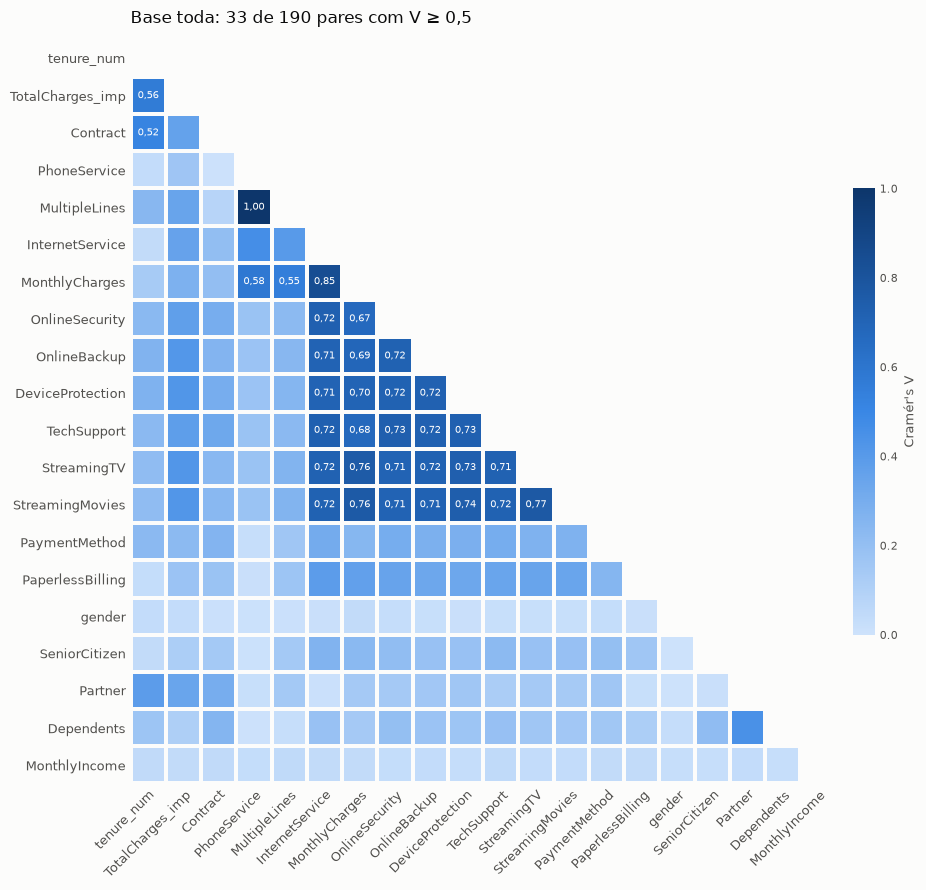

,variavel_a,variavel_b,v
0,PhoneService,MultipleLines,1.000
1,InternetService,MonthlyCharges,0.848
2,StreamingTV,StreamingMovies,0.771
3,MonthlyCharges,StreamingMovies,0.762
4,MonthlyCharges,StreamingTV,0.761
5,DeviceProtection,StreamingMovies,0.738
6,DeviceProtection,StreamingTV,0.734
7,OnlineSecurity,TechSupport,0.733
8,DeviceProtection,TechSupport,0.726
9,InternetService,OnlineSecurity,0.725


In [5]:
v_base = matriz_v(hist)
pares_base = pares_redundantes(v_base)
heatmap_v(v_base, f"Base toda: {len(pares_base)} de 190 pares com V ≥ 0,5")
pares_base.round(3)

**Resposta:** 33 dos 190 pares têm V ≥ 0,5, e a maioria envolve os serviços adicionais, `InternetService` ou `MonthlyCharges`.

- **`PhoneService` e `MultipleLines` (V = 1,00):** `MultipleLines` já contém `PhoneService` por inteiro, porque `No phone service` só existe quando `PhoneService = No`.
- **`InternetService` e `MonthlyCharges` (0,85):** o tipo de internet é o que mais define o valor da conta.
- **Serviços adicionais entre si (0,71 a 0,77):** esses valores parecem altos, mas podem vir do grupo sem internet, que todos compartilham. A pergunta 3 testa isso.
- **`tenure` e `TotalCharges` (0,56) e `tenure` e `Contract` (0,52):** passam do corte, mas com valores mais baixos.

### 3. Os serviços adicionais continuam redundantes só entre clientes com internet?

Clientes com internet: 4401
Pares com V >= 0,5: base toda = 33 | com internet = 8
Maior V entre dois serviços: base toda = 0.771 | com internet = 0.433


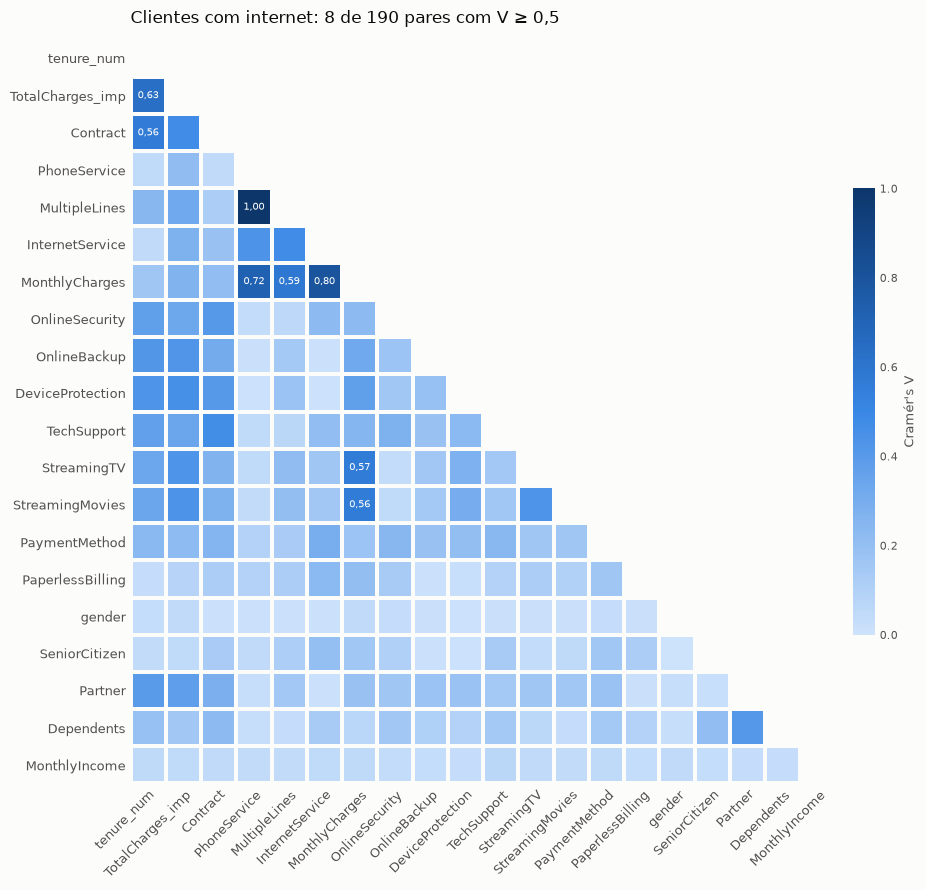

,variavel_a,variavel_b,v
0,PhoneService,MultipleLines,1.000
1,InternetService,MonthlyCharges,0.802
2,PhoneService,MonthlyCharges,0.720
3,tenure_num,TotalCharges_imp,0.633
4,MultipleLines,MonthlyCharges,0.589
5,MonthlyCharges,StreamingTV,0.566
6,MonthlyCharges,StreamingMovies,0.565
7,tenure_num,Contract,0.561


In [6]:
com_internet = hist[hist["InternetService"] != "No"]
v_internet = matriz_v(com_internet)
pares_internet = pares_redundantes(v_internet)


def maior_v_entre_servicos(m):
    return max(m.loc[a, b] for a, b in itertools.combinations(ADDONS, 2))


print(f"Clientes com internet: {len(com_internet)}")
print(f"Pares com V >= 0,5: base toda = {len(pares_base)} | com internet = {len(pares_internet)}")
print(f"Maior V entre dois serviços: base toda = {maior_v_entre_servicos(v_base):.3f} | "
      f"com internet = {maior_v_entre_servicos(v_internet):.3f}")
heatmap_v(v_internet, f"Clientes com internet: {len(pares_internet)} de 190 pares com V ≥ 0,5")
pares_internet.round(3)

**Resposta:** **não.** Entre os 4.401 clientes com internet, os pares com V ≥ 0,5 caem de 33 para 8, e nenhum deles liga dois serviços adicionais. O maior V entre serviços cai de 0,77 para 0,43 (`StreamingTV` e `StreamingMovies`). A redundância na base toda vinha quase toda da categoria `No internet service`.

Isso tem uma consequência prática: **as seis colunas `No internet service` repetem exatamente `InternetService = No`** (0 violações na pergunta 8 do notebook 03). Ao montar as variáveis do modelo, basta manter o Sim/Não de cada serviço e deixar a informação de não ter internet só em `InternetService`.

Os streamings seguem acima do corte com `MonthlyCharges` (cerca de 0,57) porque cada um soma R$ 10 à conta.

### 4. Com quais variáveis ficamos em cada grupo redundante?

In [7]:
def information_value(coluna, alvo):
    """IV da variável, com o mesmo cálculo do notebook 04."""
    t = alvo.groupby(criar_faixas(coluna), observed=True).agg(clientes="size", churners="sum")
    t["nao_churners"] = t["clientes"] - t["churners"]
    pct_churners = t["churners"].replace(0, 0.5) / t["churners"].sum()
    pct_nao_churners = t["nao_churners"].replace(0, 0.5) / t["nao_churners"].sum()
    return ((pct_nao_churners - pct_churners) * np.log(pct_nao_churners / pct_churners)).sum()


GRUPOS = {
    "tempo": ["tenure_num", "TotalCharges_imp"],
    "telefonia": ["PhoneService", "MultipleLines"],
    "internet e preço": ["InternetService", "MonthlyCharges"],
}
linhas = []
for grupo, variaveis in GRUPOS.items():
    ivs = {c: information_value(hist[c], y) for c in variaveis}
    melhor = max(ivs, key=ivs.get)
    for c, iv in ivs.items():
        linhas.append({"grupo": grupo, "variavel": c, "iv": iv, "indicacao": "manter" if c == melhor else "candidata a sair"})
indicacoes = pd.DataFrame(linhas)

candidatas = indicacoes.loc[indicacoes["indicacao"] == "candidata a sair", "variavel"].tolist()
restantes = [c for c in PREDITORAS if c not in candidatas]
print("Pares com V >= 0,5 entre clientes com internet, sem as candidatas:")
print(pares_redundantes(v_internet.loc[restantes, restantes]).round(3).to_string(index=False), "\n")
indicacoes.round(4)

Pares com V >= 0,5 entre clientes com internet, sem as candidatas:
variavel_a variavel_b     v
tenure_num   Contract 0.561 



,grupo,variavel,iv,indicacao
0,tempo,tenure_num,0.7689,manter
1,tempo,TotalCharges_imp,0.3138,candidata a sair
2,telefonia,PhoneService,0.0005,candidata a sair
3,telefonia,MultipleLines,0.0103,manter
4,internet e preço,InternetService,0.6275,manter
5,internet e preço,MonthlyCharges,0.3763,candidata a sair


**Resposta:** as **candidatas a sair** são `TotalCharges`, `PhoneService` e `MonthlyCharges`. Sem as três, o único par com V ≥ 0,5 entre clientes com internet é `tenure` e `Contract`.

| Grupo | Manter | Candidata a sair | Motivo |
|---|---|---|---|
| Tempo | `tenure` (IV 0,77) | `TotalCharges` (IV 0,31) | É quase `MonthlyCharges × tenure`. |
| Telefonia | `MultipleLines` (IV 0,010) | `PhoneService` (IV 0,001) | `MultipleLines` já contém `PhoneService`. As duas estão sem poder no notebook 04. |
| Internet e preço | `InternetService` (IV 0,63) | `MonthlyCharges` (IV 0,38) | É quase a soma dos serviços (R² = 0,999, pergunta 11 do notebook 03). |

**`tenure` e `Contract` ficam, apesar de V = 0,56.** Os grupos acima foram definidos por julgamento, não por um cálculo automático. As duas têm IV alto (0,77 e 1,17) e medem coisas diferentes: o tempo de casa e o compromisso assumido. Clientes antigos tendem a ter contratos mais longos, mas uma variável não substitui a outra, e o modelo pode testar isso.

**`MonthlyCharges` continua necessária para o valor financeiro**, mesmo que saia como variável preditora: é ela que estima a receita em risco.

## Limites desta análise

- **O V subestima relações monotônicas entre numéricas:** `tenure` e `TotalCharges` têm Spearman de 0,889, mas V de 0,56. Por isso, entre numéricas, vale olhar primeiro a pergunta 1. `MonthlyCharges` e `TotalCharges`, por exemplo, nem passam do corte de V.
- **A análise por pares não pega a redundância entre várias variáveis:** `MonthlyCharges` é a soma de vários serviços. Essa relação vem do notebook 03, não destes pares.
- **Alto V não prova que retirar a variável é seguro:** o efeito real no desempenho só aparece ao comparar modelos com e sem ela.